# 01 · ECG Analysis — MIT-BIH Arrhythmia Database

Exploratory analysis of the [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/)
(48 half-hour two-lead recordings, 360 Hz, ~110k annotated beats).

1. Download and inspect raw signals and annotations
2. Signal filtering (baseline wander / noise) and its spectrum
3. Beat class distribution (AAMI N / S / V / F / Q)
4. Average beat morphology per class
5. Rhythm (RR-interval) features per class
6. Heart rate per record
7. Validate the R-peak detector the API uses on unannotated signals

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "mitdb"
MODEL_DIR = ROOT / "models"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal as sps

from app.ecg import mitbih
from app.ecg.preprocessing import (
    AAMI_CLASSES, AAMI_DESCRIPTIONS, RR_FEATURES, SYMBOL_TO_AAMI, TARGET_FS, WINDOW_BEFORE,
    bandpass, compute_rr_features, detect_r_peaks, segment_beats,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 4)

## 1. Download & inspect a record

In [3]:
mitbih.download(DATA_DIR)  # ~100 MB, skipped if already present
sig, ann_samples, ann_symbols, fs = mitbih.load_record(DATA_DIR, "100")
print(f"fs = {fs} Hz, duration = {len(sig) / fs / 60:.1f} min, annotations = {len(ann_symbols)}")
pd.Series(ann_symbols).value_counts().rename("count").to_frame().T

fs = 360 Hz, duration = 30.1 min, annotations = 2274


,N,A,+,V
count,2239,33,1,1


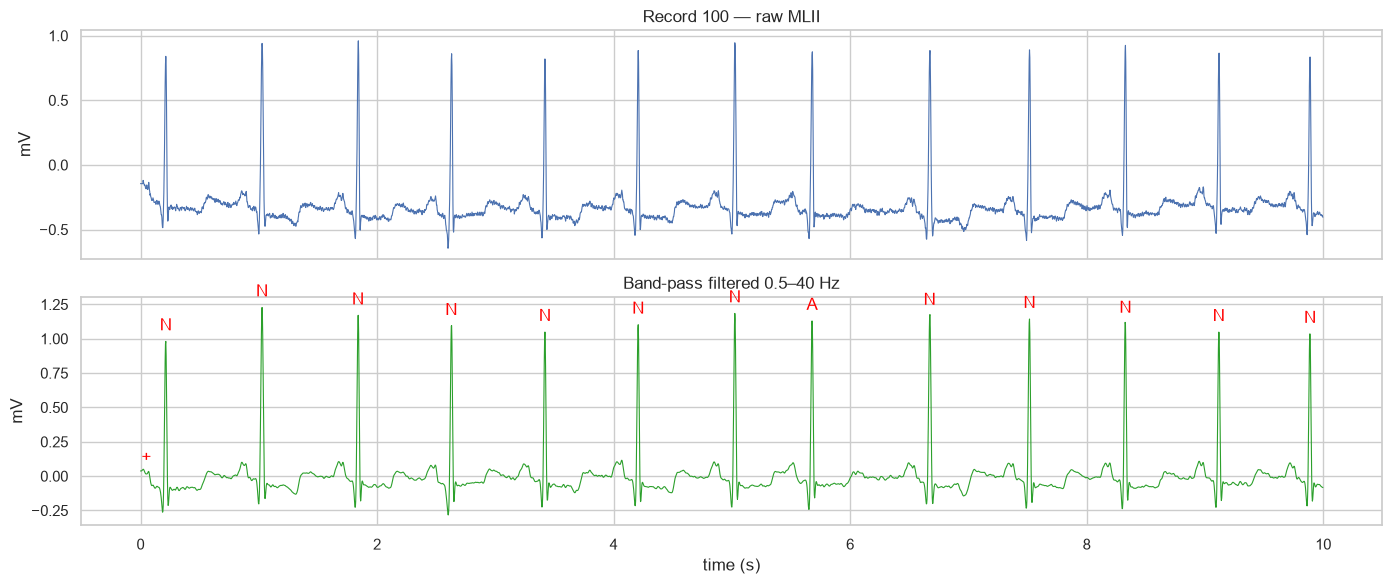

In [4]:
seconds = 10
n = seconds * fs
t = np.arange(n) / fs
filtered = bandpass(sig, fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(t, sig[:n], lw=0.8)
axes[0].set_title("Record 100 — raw MLII")
axes[1].plot(t, filtered[:n], lw=0.8, color="tab:green")
axes[1].set_title("Band-pass filtered 0.5–40 Hz")
mask = ann_samples < n
for s, sym in zip(ann_samples[mask], ann_symbols[mask]):
    axes[1].annotate(sym, (s / fs, filtered[s]), xytext=(0, 8), textcoords="offset points", ha="center", color="red")
axes[1].set_xlabel("time (s)")
for ax in axes:
    ax.set_ylabel("mV")
plt.tight_layout()

## 2. Spectrum before and after filtering

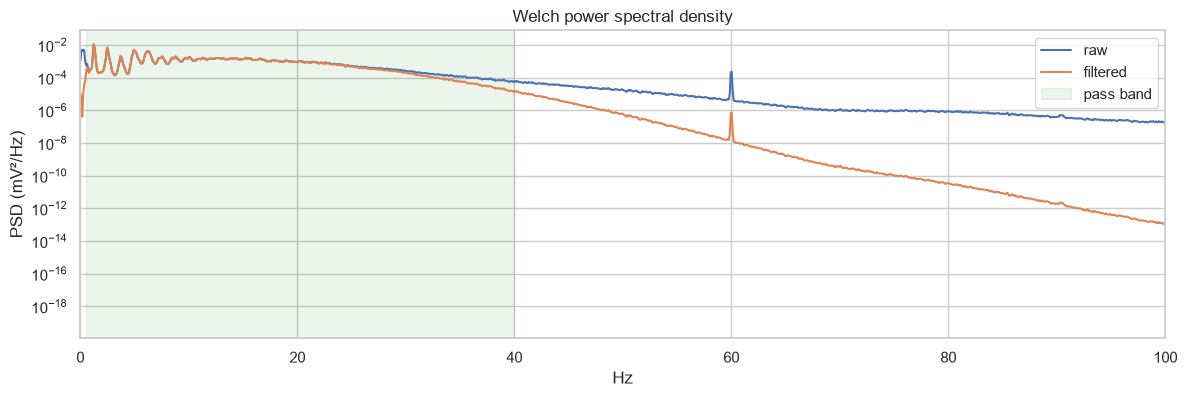

In [5]:
f_raw, p_raw = sps.welch(sig, fs=fs, nperseg=4096)
f_flt, p_flt = sps.welch(filtered, fs=fs, nperseg=4096)
plt.semilogy(f_raw, p_raw, label="raw")
plt.semilogy(f_flt, p_flt, label="filtered")
plt.axvspan(0.5, 40, color="green", alpha=0.08, label="pass band")
plt.xlim(0, 100); plt.xlabel("Hz"); plt.ylabel("PSD (mV²/Hz)"); plt.legend(); plt.title("Welch power spectral density");

## 3. Beat class distribution across all 48 records

Total annotated beats: 109,494


,count,percent,description
N,90631,82.77,Normal / bundle branch block / escape beat
S,2781,2.54,Supraventricular ectopic beat
V,7236,6.61,Ventricular ectopic beat
F,803,0.73,Fusion of ventricular and normal beat
Q,8043,7.35,Paced / unclassifiable beat


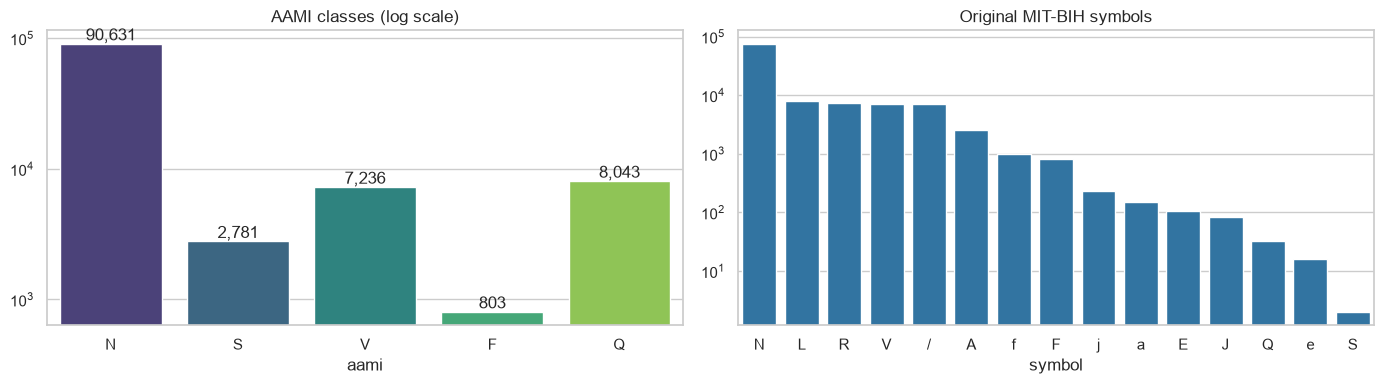

In [6]:
rows = []
for rec in mitbih.ALL_RECORDS:
    _, samples, symbols, _ = mitbih.load_record(DATA_DIR, rec)
    for sym in symbols:
        if sym in SYMBOL_TO_AAMI:
            rows.append((rec, sym, SYMBOL_TO_AAMI[sym]))
beats_df = pd.DataFrame(rows, columns=["record", "symbol", "aami"])
print(f"Total annotated beats: {len(beats_df):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = beats_df["aami"].value_counts().reindex(AAMI_CLASSES)
sns.barplot(x=order.index, y=order.values, ax=axes[0], palette="viridis", hue=order.index, legend=False)
axes[0].set_yscale("log"); axes[0].set_title("AAMI classes (log scale)")
for i, v in enumerate(order.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
sym_counts = beats_df["symbol"].value_counts()
sns.barplot(x=sym_counts.index, y=sym_counts.values, ax=axes[1], color="tab:blue")
axes[1].set_yscale("log"); axes[1].set_title("Original MIT-BIH symbols")
plt.tight_layout()

pd.DataFrame({"count": order, "percent": (100 * order / order.sum()).round(2), "description": pd.Series(AAMI_DESCRIPTIONS)})

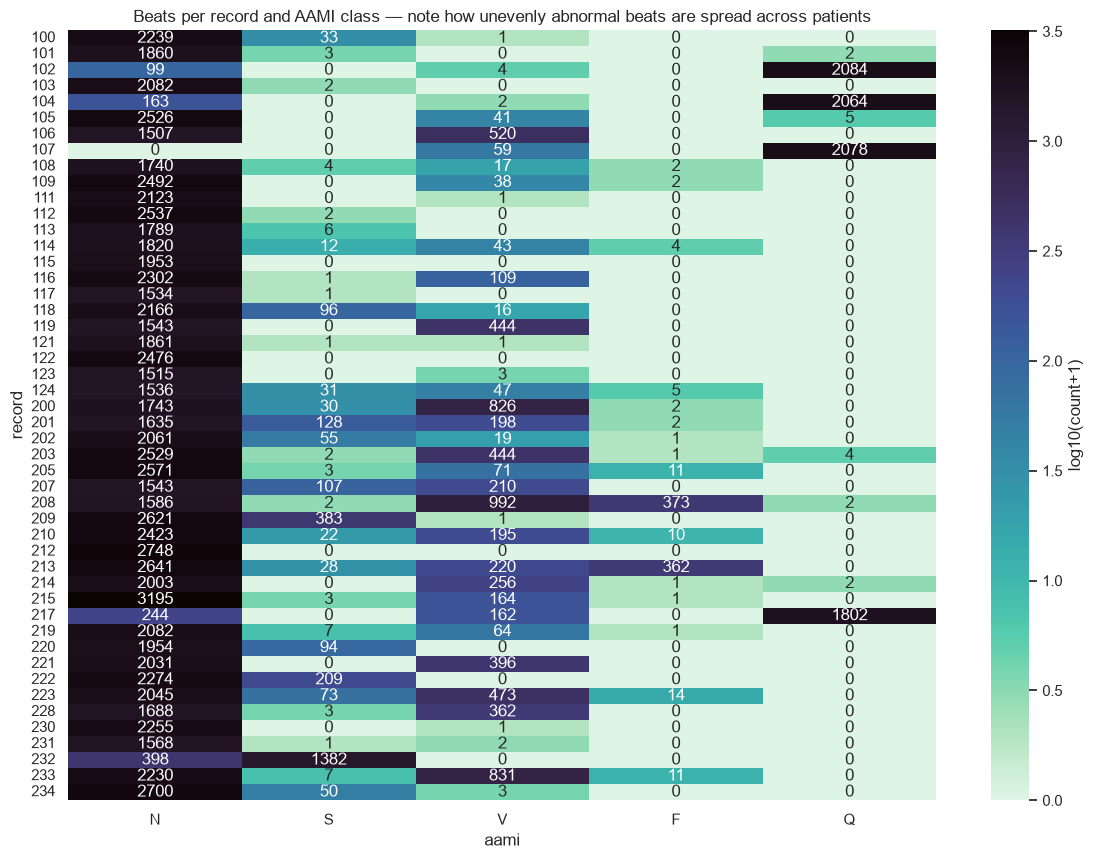

In [7]:
per_record = pd.crosstab(beats_df["record"], beats_df["aami"]).reindex(columns=AAMI_CLASSES, fill_value=0)
plt.figure(figsize=(14, 10))
sns.heatmap(np.log10(per_record + 1), annot=per_record, fmt="d", cmap="mako_r", cbar_kws={"label": "log10(count+1)"})
plt.title("Beats per record and AAMI class — note how unevenly abnormal beats are spread across patients");

## 4. Average beat morphology per class

{'beats': (100694, 256), 'rr': (100694, 4), 'labels': (100694,), 'record': (100694,), 'peak': (100694,)}


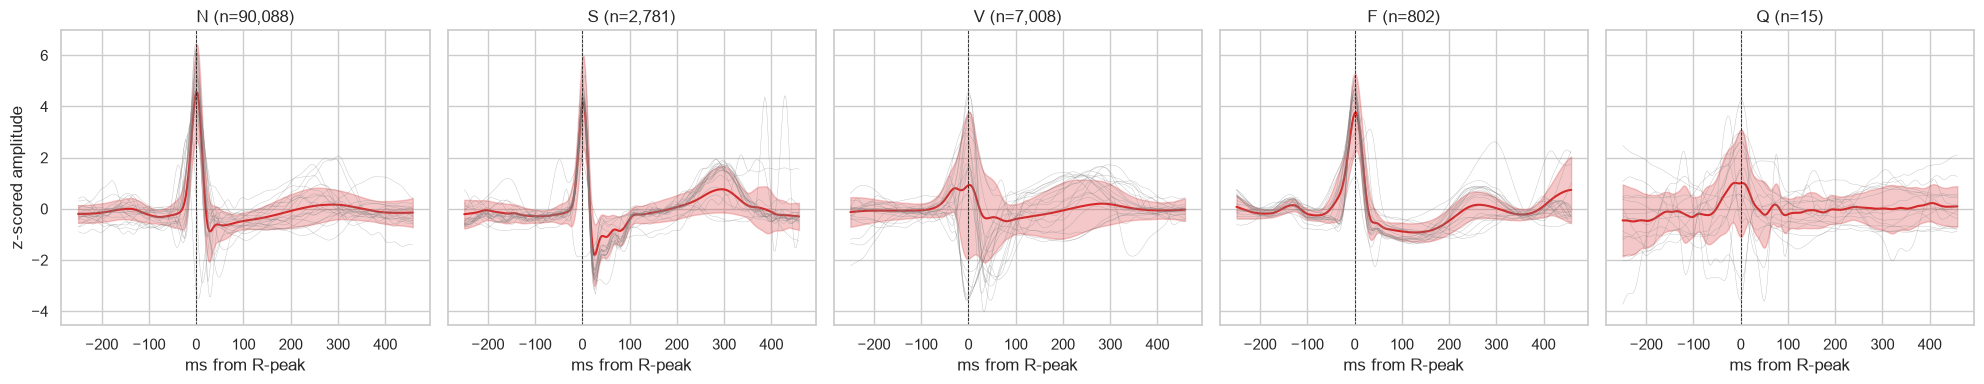

In [8]:
data = mitbih.build_dataset(DATA_DIR, mitbih.DS1 + mitbih.DS2)
print({k: v.shape for k, v in data.items()})

t_ms = (np.arange(data["beats"].shape[1]) - WINDOW_BEFORE) / TARGET_FS * 1000
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, cls in zip(axes, AAMI_CLASSES):
    b = data["beats"][data["labels"] == cls]
    if len(b) == 0:
        ax.set_title(f"{cls} (n=0)"); continue
    m, s = b.mean(0), b.std(0)
    ax.plot(t_ms, m, color="tab:red")
    ax.fill_between(t_ms, m - s, m + s, alpha=0.25, color="tab:red")
    for i in np.random.default_rng(0).choice(len(b), min(20, len(b)), replace=False):
        ax.plot(t_ms, b[i], color="grey", lw=0.3, alpha=0.5)
    ax.axvline(0, ls="--", color="k", lw=0.6)
    ax.set_title(f"{cls} (n={len(b):,})"); ax.set_xlabel("ms from R-peak")
axes[0].set_ylabel("z-scored amplitude")
plt.tight_layout()

## 5. Rhythm features per class
Supraventricular beats look almost normal but arrive early — the pre-RR ratio separates them far better than morphology.

,pre_rr_local,post_rr_local,pre_rr_global,pre_post_ratio
aami,,,,
F,0.992,0.975,1.000,1.029
N,1.003,0.996,1.006,1.008
Q,1.048,1.016,1.097,0.983
S,0.755,0.984,0.910,0.947
V,0.715,1.254,0.713,0.578


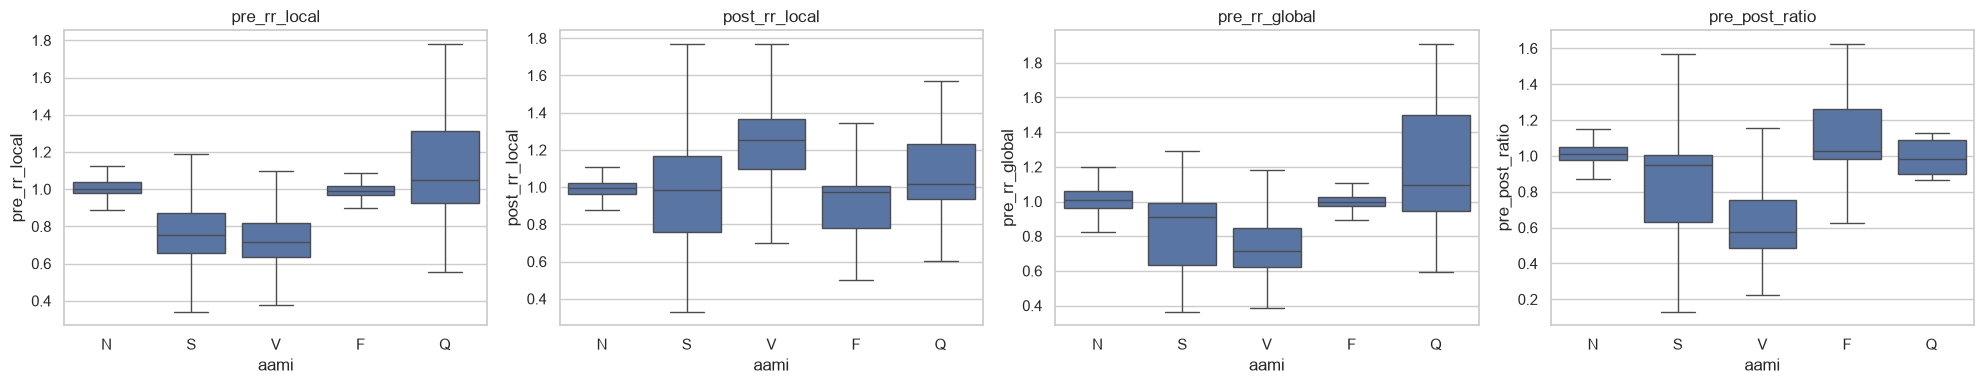

In [9]:
rr_df = pd.DataFrame(data["rr"], columns=RR_FEATURES)
rr_df["aami"] = data["labels"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, RR_FEATURES):
    sns.boxplot(data=rr_df, x="aami", y=col, order=[c for c in AAMI_CLASSES if c in set(rr_df.aami)], ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
rr_df.groupby("aami")[RR_FEATURES].median().round(3)

## 6. Heart rate per record

,mean_hr,sdnn_ms
count,48.0,48.0
mean,75.8,173.3
std,15.0,341.5
min,50.4,21.7
25%,65.1,48.2
50%,73.7,91.1
75%,85.7,180.7
max,111.8,2364.3


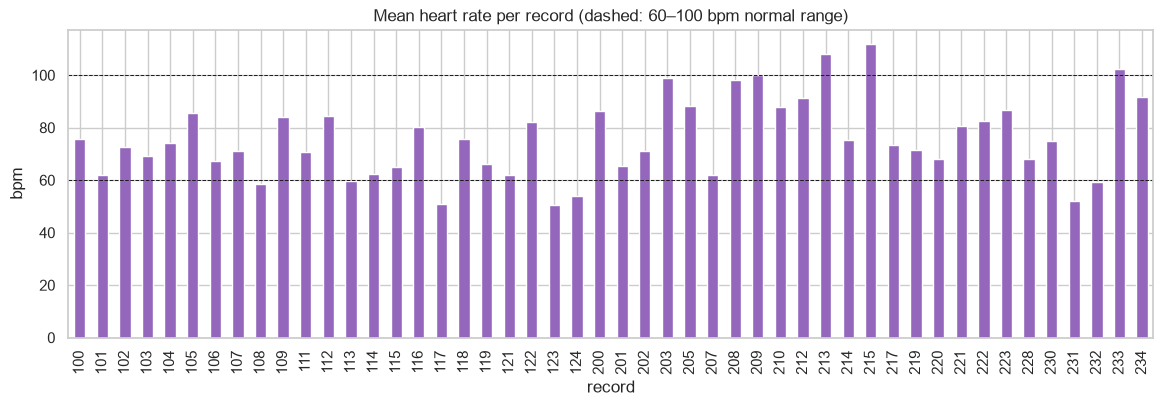

In [10]:
hr_rows = []
for rec in mitbih.ALL_RECORDS:
    _, samples, symbols, fs_ = mitbih.load_record(DATA_DIR, rec)
    peaks = samples[np.isin(symbols, list(SYMBOL_TO_AAMI))]
    rr = np.diff(peaks) / fs_
    hr_rows.append({"record": rec, "mean_hr": 60 / rr.mean(), "sdnn_ms": rr.std() * 1000})
hr_df = pd.DataFrame(hr_rows).set_index("record")
ax = hr_df["mean_hr"].plot(kind="bar", figsize=(14, 4), color="tab:purple")
ax.axhline(60, ls="--", c="k", lw=0.7); ax.axhline(100, ls="--", c="k", lw=0.7)
ax.set_ylabel("bpm"); ax.set_title("Mean heart rate per record (dashed: 60–100 bpm normal range)")
hr_df.describe().round(1)

## 7. Validate the R-peak detector
The API must detect R-peaks itself on user-supplied ECG. Compare against cardiologist annotations (±50 ms tolerance).

In [11]:
def detector_scores(rec, tol_s=0.05):
    sig_, samples, symbols, fs_ = mitbih.load_record(DATA_DIR, rec)
    ref = samples[np.isin(symbols, list(SYMBOL_TO_AAMI))]
    det = detect_r_peaks(bandpass(sig_, fs_), fs_)
    tol = int(tol_s * fs_)
    idx = np.searchsorted(det, ref)
    left = np.abs(ref - det[np.clip(idx - 1, 0, len(det) - 1)])
    right = np.abs(ref - det[np.clip(idx, 0, len(det) - 1)])
    tp = int((np.minimum(left, right) <= tol).sum())
    return {"record": rec, "ref": len(ref), "detected": len(det), "sensitivity": tp / len(ref), "ppv": min(tp / max(len(det), 1), 1.0)}

det_df = pd.DataFrame([detector_scores(r) for r in mitbih.DS1 + mitbih.DS2]).set_index("record")
print(f"Mean sensitivity {det_df.sensitivity.mean():.3f} · mean PPV {det_df.ppv.mean():.3f}")
det_df.sort_values("sensitivity").head(10).round(3)

Mean sensitivity 0.963 · mean PPV 0.993


,ref,detected,sensitivity,ppv
record,,,,
106,2027,1455,0.717,0.999
223,2605,2053,0.788,1.000
108,1763,1492,0.829,0.980
222,2483,2079,0.836,0.999
203,2980,2663,0.873,0.977
208,2955,2626,0.887,0.998
228,2053,1914,0.906,0.972
210,2650,2433,0.915,0.996
214,2262,2248,0.942,0.948


## Takeaways

- Classes are **heavily imbalanced** (N ≫ V > S ≫ F); training needs class weighting.
- Abnormal beats are concentrated in a few patients → evaluate **inter-patient** (DS1 → DS2) to avoid optimistic numbers.
- S beats are morphologically close to N; **RR features relative to the patient's own rhythm** are essential and are fed to the LSTM alongside the waveform.
- 90% of fusion (F) beats come from a single patient (208), so F cannot be learned in a way that generalises to new patients.
- The simple R-peak detector is good enough for most records; difficult records (noise, paced, bigeminy) drag it down.

Next: `02_lstm_training.ipynb`.